Student Dataset:
   Student  Hours_Studied  Marks
0        1              2     35
1        2              3     40
2        3              4     43
3        4              5     48
4        5              6     52
5        6              7     57
6        7              8     61
7        8              9     66
8        9             10     70
9       10             11     74

K-Fold R2 Scores:
Fold 1: 0.9982
Fold 2: 0.9997
Fold 3: 0.9962
Fold 4: 0.9982
Fold 5: 0.9996

Average R2 Score: 0.9984

Actual Marks:
[35, 40, 43, 48, 52, 57, 61, 66, 70, 74]

Predicted Marks:
[34.96 39.33 43.69 48.05 52.42 56.78 61.15 65.51 69.87 74.24]

Mean Squared Error: 0.1491
R2 Score: 0.9991

Linear Regression Equation:
Marks = 26.24 + 4.36 * Hours_Studied


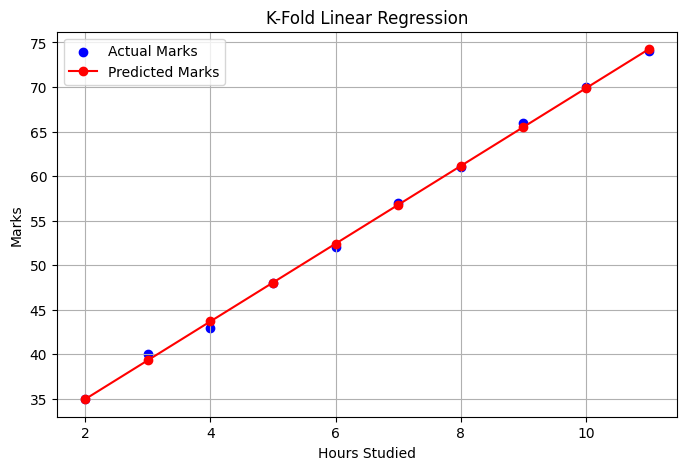

In [1]:

# K-Fold Cross Validation using Linear Regression

# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

# Step 2: Create Dataset
data = {
    'Student': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Hours_Studied': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
    'Marks': [35, 40, 43, 48, 52, 57, 61, 66, 70, 74]
}

df = pd.DataFrame(data)

print("Student Dataset:")
print(df)

# Step 3: Separate Input and Output Variables
X = df[['Hours_Studied']]
y = df['Marks']

# Step 4: Create Linear Regression Model
model = LinearRegression()

# Step 5: Apply K-Fold Cross Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    model,
    X,
    y,
    cv=kf,
    scoring='r2'
)

print("\nK-Fold R2 Scores:")
for i, score in enumerate(scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nAverage R2 Score:", round(scores.mean(), 4))

# Step 6: Train Model on Complete Dataset
model.fit(X, y)

# Step 7: Predict Marks
y_pred = model.predict(X)

print("\nActual Marks:")
print(list(y))

print("\nPredicted Marks:")
print(np.round(y_pred, 2))

# Step 8: Evaluate Model
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("\nMean Squared Error:", round(mse, 4))
print("R2 Score:", round(r2, 4))

# Step 9: Display Regression Equation
print("\nLinear Regression Equation:")
print(f"Marks = {model.intercept_:.2f} + {model.coef_[0]:.2f} * Hours_Studied")

# Step 10: Visualize Results
plt.figure(figsize=(8, 5))

plt.scatter(X['Hours_Studied'], y,
            color='blue', label='Actual Marks')

plt.plot(X['Hours_Studied'], y_pred,
         color='red', marker='o',
         label='Predicted Marks')

plt.xlabel('Hours Studied')
plt.ylabel('Marks')
plt.title('K-Fold Linear Regression')
plt.legend()
plt.grid(True)

plt.show()
